# **PREPROCESADO**

In [24]:
# ── DEPENDENCIAS · una sola orden, y la primera celda del cuaderno ───────────
#  Este cuaderno no sale a la red: parte de `df_new_features.parquet`, que
#  escribe LIMPIEZA_Y_CREACION_DE_VARS_trabajo.ipynb. `seaborn` y `matplotlib`
#  son para el mapa de valores faltantes; `pytz` para que RUN_DATE se calcule
#  con el mismo huso (Europe/Madrid) que los otros dos cuadernos.

!pip install -q pandas numpy pyarrow pytz seaborn matplotlib

In [25]:
# =============================================================================
#  CELDA · PARAMETROS, RUTAS Y LAS DOS TEMPORADAS
# -----------------------------------------------------------------------------
#  Identica a la celda homonima de EXTRACCION_DATOS_v13_trabajo.ipynb, a
#  proposito: los dos cuadernos cuelgan del MISMO `ROOT` y de la MISMA
#  convencion de nombre de artefacto (`art()`/`art_sella()`), así que este
#  cuaderno lee con `art("fd_xg_elo_transfermarkt_wk_sofa")` lo que el otro
#  acaba de escribir sin que haya que teclear un nombre de fichero en
#  ningun sitio. Repetirla aqui en vez de importarla no es duplicacion
#  ociosa: cada cuaderno es su propio kernel y no hereda nada del otro.
# =============================================================================

from pathlib import Path
from datetime import datetime
import re
import pandas as pd
import pytz

TZ = pytz.timezone("Europe/Madrid")

if "RUN_DATE" in globals() and globals()["RUN_DATE"]:
    _run_date = str(globals()["RUN_DATE"])
else:
    _run_date = datetime.now(TZ).date().strftime("%Y-%m-%d")

RUN_DATE = pd.to_datetime(_run_date, errors="coerce").date().strftime("%Y-%m-%d")


def temporada_de_partido(fechas):
    """Temporada a la que PERTENECE un partido, como año de inicio. Corte en
    AGOSTO (ver EXTRACCION_DATOS_v13_trabajo.ipynb, celda de parametros)."""
    d = pd.to_datetime(pd.Series(fechas), errors="coerce")
    return (d.dt.year - (d.dt.month < 8)).astype("Int64")


def temporada_a_pedir(hoy=None):
    """Temporada que hay que PEDIRLE hoy a una fuente, como año de inicio.
    Corte en JULIO (ver el mismo sitio)."""
    h = pd.to_datetime(hoy if hoy is not None else RUN_DATE)
    return int(h.year) - (1 if h.month < 7 else 0)


if "SEASON" in globals() and globals()["SEASON"]:
    SEASON = globals()["SEASON"]
else:
    _y = temporada_a_pedir()
    SEASON = f"{_y}_{(_y + 1) % 100:02d}"

MATCHDAY = globals().get("MATCHDAY", None)
MODEL_VERSION = globals().get("MODEL_VERSION", "xgb-local")

if globals().get("ROOT"):
    ROOT, _VIA = Path(globals()["ROOT"]), "ROOT inyectada"
else:
    ROOT, _VIA = Path.cwd(), "carpeta de trabajo del cuaderno"

DATA = ROOT / "data"
RAW = DATA / "01_raw"
PROC = DATA / "02_processed"
FEAT = DATA / "03_features"
MODELS = DATA / "04_models"
OUT = ROOT / "outputs"
MANUAL = ROOT / "manual"

for p in [RAW, PROC, FEAT, MODELS, OUT, MANUAL]:
    p.mkdir(parents=True, exist_ok=True)

# --- NOMBRE DE ARTEFACTO: el rango lo pone el dato, no la mano --------------
ART_ETIQUETA = re.compile(
    r"^(?P<stem>.+?)_(?P<a>\d{4})(?:-\d{2})?_(?P<b>\d{4})(?:-\d{2})?$")


def _temp_etiqueta(y):
    y = int(y)
    return f"{y}-{(y + 1) % 100:02d}"


def temporadas_de(df):
    """Etiqueta '2005-06_2026-27' con el rango de temporadas que hay en `df`.
    Identica a la de EXTRACCION_DATOS_v13_trabajo.ipynb."""
    y = None
    for _c in ("season_year", "Season"):
        if _c in df.columns:
            y = pd.to_numeric(df[_c], errors="coerce").dropna()
            break
    if y is None and "season" in df.columns:
        y = pd.to_numeric(df["season"].astype(str).str.slice(0, 4),
                          errors="coerce").dropna()
    if y is None:
        for _c in ("date", "Date"):
            if _c in df.columns and pd.api.types.is_datetime64_any_dtype(df[_c]):
                y = temporada_de_partido(df[_c]).dropna()
                break
    if y is None:
        raise KeyError(
            "no hay de donde leer la temporada para nombrar el artefacto: se "
            "buscan 'season_year', 'Season', 'season' y una fecha ya en "
            f"datetime. Columnas: {list(df.columns)[:10]}")
    if not len(y):
        raise ValueError("la columna de temporada no tiene ni un valor valido")
    return f"{_temp_etiqueta(y.min())}_{_temp_etiqueta(y.max())}"


def _art_candidatas(stem, base, alias=()):
    vistas, salida = set(), []
    for p in (sorted(base.glob(f"{stem}_*.parquet"))
              + [base / f"{stem}.parquet"] + [base / a for a in alias]):
        if p.name in vistas or not p.exists():
            continue
        m = ART_ETIQUETA.match(p.stem)
        if (p.stem != stem and p.name not in alias
                and not (m and m.group("stem") == stem)):
            continue
        vistas.add(p.name)
        salida.append(((int(m.group("b")), -int(m.group("a"))) if m else (-1, 0),
                       p.stat().st_mtime, p))
    return [t[2] for t in sorted(salida, key=lambda t: (t[0], t[1]), reverse=True)]


def art(stem, alias=(), base=None):
    """Via del artefacto `stem` con la que trabajar en ESTA ejecucion."""
    base = Path(base) if base else PROC
    hay = _art_candidatas(stem, base, alias)
    if len(hay) > 1:
        print(f"   AVISO: {len(hay)} versiones de '{stem}' en disco "
              f"({', '.join(p.name for p in hay)}). Se trabaja con la "
              "primera; `art_sella` retira el resto al escribir.")
    return hay[0] if hay else base / f"{stem}.parquet"


def art_sella(stem, via, df, alias=()):
    """Pone a `via` el rango real de `df` y retira las versiones anteriores."""
    via = Path(via)
    try:
        destino = via.with_name(f"{stem}_{temporadas_de(df)}.parquet")
    except (KeyError, ValueError) as _e:
        print(f"   AVISO: {via.name} se queda con su nombre ({_e})")
        return via
    if destino != via:
        via.replace(destino)
        _vb, _db = Path(f"{via}.bak"), Path(f"{destino}.bak")
        if _vb.exists():
            _vb.replace(_db)
        print(f"   nombre       {via.name} -> {destino.name}")
    import pyarrow.parquet as _pq
    for p in _art_candidatas(stem, destino.parent, alias):
        if p == destino:
            continue
        try:
            _n = _pq.ParquetFile(p).metadata.num_rows
        except Exception:
            _n = -1
        if _n > len(df):
            print(f"   AVISO: se deja {p.name}, que tiene {_n} filas, mas que "
                  f"las {len(df)} que se acaban de escribir. Mira cual manda "
                  "antes de borrarlo.")
            continue
        for _q in (p, Path(f"{p}.bak")):
            _q.unlink(missing_ok=True)
        print(f"   retirado     {p.name}")
    return destino


# --- Puerta de escritura: se prueba, no se supone ---------------------------
_cent = PROC / "_centinela_escritura.txt"
try:
    _cent.write_text(RUN_DATE, encoding="utf-8")
    if _cent.read_text(encoding="utf-8") != RUN_DATE:
        raise OSError("lo leido no es lo escrito")
    _cent.unlink(missing_ok=True)
except Exception as _e:
    raise OSError(
        f"no se puede escribir en {PROC} ({type(_e).__name__}: {_e}). "
        "Comprueba permisos y cuota; si la carpeta la sincroniza OneDrive, "
        "puede haber marcado algun fichero de solo lectura."
    ) from _e

print(f"RUN_DATE = {RUN_DATE} | SEASON = {SEASON} | MATCHDAY = {MATCHDAY} | "
      f"MODEL_VERSION = {MODEL_VERSION}")
print(f"ROOT = {ROOT}   ({_VIA})")
print(f"escritura verificada en {PROC}")


RUN_DATE = 2026-11-16 | SEASON = 2026_27 | MATCHDAY = None | MODEL_VERSION = xgb-local
ROOT = c:\Users\admin\Desktop\ultimo proyecto   (ROOT inyectada)
escritura verificada en c:\Users\admin\Desktop\ultimo proyecto\data\02_processed


In [26]:
# =============================================================================
#  CELDA · LOS IMPORTES DEL CUADERNO
# =============================================================================
import json

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("importes listos")

importes listos


# Eliminación de Variables

Tras la extracción de los datos, llevé a cabo una selección de variables en función del número de valores faltantes que tuviese. Finalmente me quede con todas las variables que no tenian ningún missing (excepto las de xG) ya que eran justo las que necesitaba en un principio.

Después me puse a crear nuevas variables, por lo que se habrán creado nuevos missings que deben ser tratados con cuidado.

Además, este será el preparatorio previo al modelaje. Hay que quedarse con un dataset formado unicamente por números y con las variables justas y necesarias.

**Lo que cambia respecto a la primera versión.** El fichero de entrada ya no tiene 117 columnas sino 359: trae las cuotas de todas las casas, la estadística de SofaScore y las variables nuevas, muchas de ellas con poco histórico. Por eso cada columna tiene ahora un **papel** declarado, y solo las de un papel entran al modelo:

* **identificación**: fecha, temporada, equipos, clave del partido;
* **objetivo**: `FTR` y `target`;
* **cuotas**: las de todas las casas, apertura y cierre. Se conservan tal cual, con sus huecos, para medir y para liquidar apuestas. **No son variables de entrada**;
* **variables**: lo que el modelo puede usar. Todas numéricas y sin huecos al terminar el cuaderno.

El cuaderno acaba guardando tres ficheros: `df_final.parquet`, que es el que lee el cuaderno de modelado y solo lleva lo que él espera (fecha, temporada, jornada, equipos, cuotas de Bet365, resultado y las variables); `df_final_completo.parquet`, con todo, incluidas las cuotas de todas las casas; y `df_final_columnas.json`, con la lista de columnas de cada papel.

In [27]:
IN_PATH = PROC / "df_new_features.parquet"
if not IN_PATH.exists():
    raise FileNotFoundError(
        f"no esta {IN_PATH}. Lo escribe la ultima celda de "
        "LIMPIEZA_Y_CREACION_DE_VARS_trabajo.ipynb.")

df = pd.read_parquet(IN_PATH)
if df["match_key"].duplicated().any():
    raise ValueError("el fichero de entrada repite partidos (match_key)")

N_JUGADOS = int(df["FTR"].notna().sum())
N_FUTUROS = int(df["FTR"].isna().sum())
print(f"cargado: {IN_PATH.name} · {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"{N_JUGADOS:,} partidos jugados + {N_FUTUROS} por predecir · "
      f"{df['season'].min()} .. {df['season'].max()}")
df

cargado: df_new_features.parquet · 8,119 filas x 359 columnas
8,109 partidos jugados + 10 por predecir · 2005/06 .. 2026/27


,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,HST,AST,...,away_relative_perf,home_perf_vs_market,away_perf_vs_market,home_line_move_last5,away_line_move_last5,overround,pimp1,pimpx,pimp2,pimp_gap
0,0.0,0.0,D,0.0,0.0,D,5.0,17.0,0.0,10.0,...,NaN,NaN,NaN,NaN,NaN,1.076190,0.132743,0.247788,0.619469,0.486726
1,3.0,0.0,H,0.0,0.0,D,10.0,9.0,6.0,2.0,...,NaN,NaN,NaN,NaN,NaN,1.115385,0.448276,0.275862,0.275862,0.172414
2,1.0,0.0,H,0.0,0.0,D,9.0,14.0,2.0,3.0,...,NaN,NaN,NaN,NaN,NaN,1.115385,0.448276,0.275862,0.275862,0.172414
3,0.0,0.0,D,0.0,0.0,D,16.0,9.0,5.0,2.0,...,NaN,NaN,NaN,NaN,NaN,1.125513,0.516560,0.261319,0.222121,0.294439
4,1.0,2.0,A,0.0,1.0,A,15.0,17.0,5.0,6.0,...,NaN,NaN,NaN,NaN,NaN,1.077778,0.123711,0.231959,0.644330,0.520619
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8114,NaN,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,...,0.854387,-0.248469,-0.247674,0.007557,0.001873,1.072651,0.345285,0.274197,0.380518,0.035233
8115,NaN,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,...,1.213686,-0.231137,0.309036,0.007369,0.003152,1.085024,0.102404,0.160285,0.737311,0.634907
8116,NaN,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,...,0.914338,0.031111,-0.016993,-0.009058,0.007052,1.074405,0.443213,0.265928,0.290859,0.152355
8117,NaN,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,...,0.860003,0.194178,-0.195018,-0.004454,-0.004174,1.086913,0.438113,0.278799,0.283088,0.155025


Lo primero es deshacernos de las variables que generan data leakage:

Son las que solo se conocen cuando el partido ha terminado. A la lista original (goles, tiros, faltas, córners, tarjetas, xG del partido y los puntos y diferencia de goles del propio partido) hay que añadir ahora la **estadística de SofaScore del propio partido** (posesión, ocasiones claras, xGOT...): lo que se usa de ella son sus medias de partidos anteriores, que ya están creadas con otro nombre.

Las cuotas de **cierre** tampoco se conocen cuando se predice, pero no se borran: pasan al papel de *cuotas*, fuera de las variables.

La celda comprueba además lo que la lista no puede garantizar por sí sola: que ninguna columna que vaya a ser variable esté vacía en todos los partidos por predecir. Una columna así es, casi siempre, un dato del propio partido que se ha colado.

In [28]:
# ── 1) lo que solo se conoce al terminar el partido: fuera ──────────────────
#  la lista de siempre
variables_to_drop = ['FTHG', 'FTAG', 'HTHG', 'HTAG', 'HTR', 'HS', 'AS', 'HST', 'AST',
                     'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR',
                     'home_points', 'away_points', 'home_gd', 'away_gd',
                     'h_xg', 'a_xg', 'pH_adj', 'pA_adj']
#  la estadistica de SofaScore DEL PROPIO PARTIDO (sus medias previas son las
#  `home_avg_..._last7`, que se quedan)
SOFA_PARTIDO = ["poss", "big_ch", "big_ch_miss", "big_ch_scored", "xgot", "gk_prev",
                "sofa_rating", "woodwork", "through_balls", "recoveries",
                "box_touches", "distance_km", "sprints"]
variables_to_drop += [f"{lado}_{a}" for a in SOFA_PARTIDO for lado in ("h", "a")]

_no_estan = [c for c in variables_to_drop if c not in df.columns]
if _no_estan:
    raise KeyError(f"columnas de la lista que el fichero no trae: {_no_estan}")
df = df.drop(columns=variables_to_drop)

# ── 2) el papel de cada columna que queda ───────────────────────────────────
IDENTIFICACION = ["date", "season", "season_year", "Matchweek", "kickoff_time",
                  "home_canon", "away_canon", "match_key",
                  "h_elo_date", "a_elo_date", "h_elo_dias", "a_elo_dias"]
OBJETIVO = ["FTR"]
#  cuotas de todas las casas y cuantas casas dan precio: se conservan con sus
#  huecos y NO entran al modelo. Lo que el modelo sabe del mercado son las
#  probabilidades ya derivadas (`pimp1/x/2`, `mkt_p_*`, `overround`, `pimp_gap`).
CUOTAS = [c for c in df.columns if c.startswith("odds_")] + ["n_books_open", "n_books_close"]

_faltan = [c for c in IDENTIFICACION + OBJETIVO if c not in df.columns]
if _faltan:
    raise KeyError(f"faltan columnas de identificacion u objetivo: {_faltan}")


def columnas_variables(d):
    """Todo lo que no es identificacion, objetivo ni cuota: lo que va al modelo."""
    fuera = set(IDENTIFICACION) | set(OBJETIVO) | set(CUOTAS) | {"target"}
    return [c for c in d.columns if c not in fuera]


# ── 3) ninguna variable puede faltar en TODOS los partidos por predecir ─────
_fut = df["FTR"].isna()
if _fut.any():
    _ult = df.loc[~_fut].tail(30)
    _colada = [c for c in columnas_variables(df)
               if df.loc[_fut, c].isna().all() and _ult[c].notna().mean() > 0.5]
    if _colada:
        raise ValueError(
            "estas columnas estan vacias en todos los partidos por predecir y no en los "
            f"ultimos jugados: {_colada}. Son datos del propio partido: añadelas a "
            "`variables_to_drop`.")

print(f"eliminadas {len(variables_to_drop)} columnas del propio partido · quedan {df.shape[1]}")
print(f"   identificacion {len(IDENTIFICACION)} · objetivo {len(OBJETIVO)} · "
      f"cuotas {len(CUOTAS)} · variables {len(columnas_variables(df))}")

eliminadas 51 columnas del propio partido · quedan 308
   identificacion 12 · objetivo 1 · cuotas 122 · variables 173


# Retraso de las variables de Transfermarkt una temporada

Retraso de las variables de tranfermarkt una temporada:

En la primera versión el retraso se hacía aquí. Ahora llega hecho del cuaderno de variables (columnas `h_..._prev` y `a_..._prev`), que además usa el valor de Segunda para los recién ascendidos cuando la tabla `transfermarkt_previa.parquet` está disponible. Aquí solo queda devolverles el nombre de siempre (`..._prev_season`) y calcular sus diferencias local − visitante.

In [29]:
variables_transfermarkt = ['avg_age', 'value_mio', 'value_avg_mio', 'squad_size', 'pct_foreigners']

# el nombre de siempre: h_<var>_prev_season / a_<var>_prev_season
_renombra = {f"{lado}_{v}_prev": f"{lado}_{v}_prev_season"
             for v in variables_transfermarkt for lado in ("h", "a")}
_no_estan = [c for c in _renombra if c not in df.columns]
if _no_estan:
    raise KeyError(f"el fichero no trae {_no_estan}: ejecuta el cuaderno de variables actual")
#  por si alguien lee un fichero antiguo: las de la temporada en curso no valen
_en_curso = [f"{lado}_{v}" for v in variables_transfermarkt for lado in ("h", "a")
             if f"{lado}_{v}" in df.columns]
if _en_curso:
    raise ValueError(f"el fichero trae Transfermarkt de la temporada en curso: {_en_curso}")
df = df.rename(columns=_renombra)

In [30]:
# Diferencias de Transfermarkt (temporada previa): home - away
variables_transfermarkt = ['avg_age', 'value_mio', 'value_avg_mio', 'squad_size', 'pct_foreigners']

for v in variables_transfermarkt:
    h = f'h_{v}_prev_season'
    a = f'a_{v}_prev_season'
    df[f'{v}_prev_season_diff'] = df[h] - df[a]

_jug = df["FTR"].notna()
print(f"Transfermarkt de la temporada anterior: "
      f"{df.loc[_jug, 'value_mio_prev_season_diff'].notna().mean():.1%} de los partidos "
      f"jugados tienen el dato de los dos equipos")

Transfermarkt de la temporada anterior: 100.0% de los partidos jugados tienen el dato de los dos equipos


# Valores faltantes

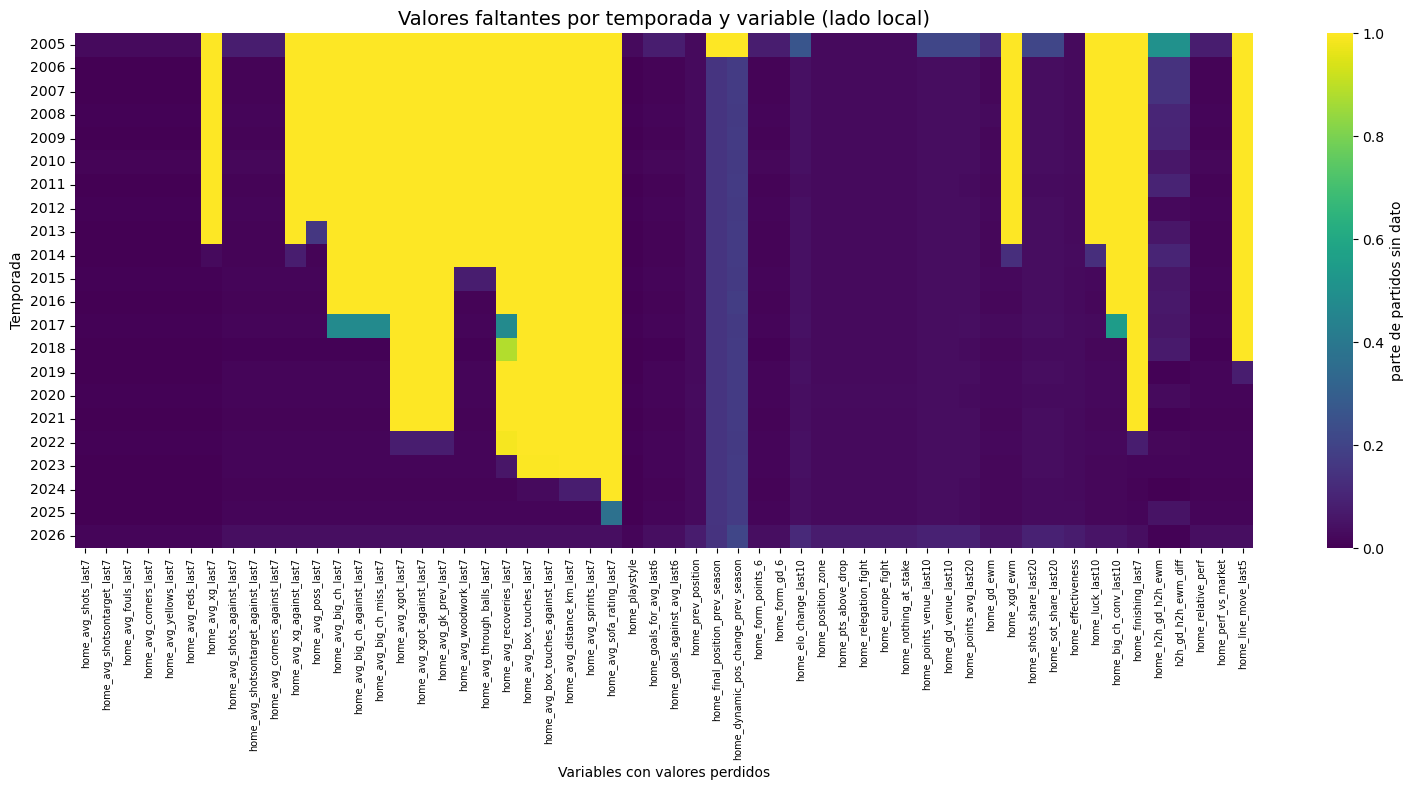

111 de 178 variables tienen algun hueco en los partidos jugados


In [31]:
#  Que parte de cada variable esta vacia en cada temporada. Se dibuja una por
#  pareja local/visitante (la del local), porque las dos tienen el mismo patron.
_vars = columnas_variables(df)
_jug = df["FTR"].notna()
_con_hueco = [c for c in _vars if df.loc[_jug, c].isna().any() and not c.startswith(("away_", "a_"))]
_mapa = df.loc[_jug].groupby("season_year")[_con_hueco].apply(lambda g: g.isna().mean())

plt.figure(figsize=(max(12, 0.28 * len(_con_hueco)), 8))
sns.heatmap(_mapa, cbar=True, cmap="viridis", vmin=0, vmax=1,
            xticklabels=True, cbar_kws={"label": "parte de partidos sin dato"})
plt.title("Valores faltantes por temporada y variable (lado local)", fontsize=14)
plt.xlabel("Variables con valores perdidos")
plt.ylabel("Temporada")
plt.xticks(fontsize=7, rotation=90)
plt.tight_layout()
plt.show()

print(f"{len([c for c in _vars if df.loc[_jug, c].isna().any()])} de {len(_vars)} variables "
      f"tienen algun hueco en los partidos jugados")

Ya que gran parte de las variables presentan la mayor parte de los missing values en la primera temporada de nuestro dataset, la temporada 05/06, procedo a eliminar dicha temporada de mi historial de partidos.

Sigue teniendo sentido: en 2005/06 ningún equipo tiene posición final del año anterior, y las ventanas largas (20 partidos, medias exponenciales) todavía se están llenando. La temporada no se pierde del todo: sus partidos ya han servido para calcular las variables de 2006/07, y aquí se guardan aparte para estimar los valores típicos con los que se rellenan los huecos más abajo.

In [32]:
PRIMERA_TEMPORADA = 2006                 # la primera que entra al modelo

historia = df.sort_values(["date", "match_key"])   # todo, 2005/06 incluida: solo para los valores tipicos
df = df[df['season_year'] >= PRIMERA_TEMPORADA].copy()

HUECOS_ANTES = df[columnas_variables(df)].isna()    # que estaba vacio antes de rellenar nada
print(f"quedan {len(df):,} partidos ({int(df['FTR'].notna().sum()):,} jugados + "
      f"{int(df['FTR'].isna().sum())} por predecir) desde {df['season'].min()}")

quedan 7,739 partidos (7,729 jugados + 10 por predecir) desde 2006/07


**Cómo se tratan los huecos.** La primera versión rellenaba casi todo con 0. Con las variables antiguas funcionaba porque sus huecos eran pocos, pero ahora hay variables enteras que no existen antes de 2014, 2017, 2022 o 2024, y para ellas el 0 no es un valor neutro: una posesión de 0 o un valor de plantilla de 0 le dicen a una regresión logística que ese equipo es el peor de la historia. Se generaliza lo que ya se hacía con el xG, en tres piezas:

1. **Un indicador por fuente** (`has_xg_data`, `has_poss_data`, `has_big_ch_data`...): vale 1 si el partido tiene ese dato para los dos equipos. Es lo que permite al modelo distinguir "no había dato" de "el dato era ese", y también lo que permite, en el cuaderno de modelado, entrenar una variable de poco histórico solo con los partidos que la tienen.
2. **Las posiciones** tienen su regla propia, como en la primera versión.
3. **El resto se rellena con el valor típico de la variable**: su mediana en las temporadas *anteriores* a la del partido. Así un hueco se lee como "un equipo normal" y nunca se usa información posterior al partido. Donde el dato no existía en ninguna temporada anterior se usa la mediana de la primera temporada que lo tiene; es una constante para toda esa época, y el indicador de la fuente ya dice que ahí no había dato.

* **avg_xg_last7** y el resto de fuentes con poco histórico

In [33]:
#  indicador -> pareja de columnas testigo. El indicador vale 1 si las dos
#  tienen dato en el partido. `has_xg_data` es el de la primera version, con
#  la misma definicion.
FUENTES = {
    "has_xg_data":            ("home_avg_xg_last7", "away_avg_xg_last7"),
    "has_poss_data":          ("home_avg_poss_last7", "away_avg_poss_last7"),
    "has_through_balls_data": ("home_avg_through_balls_last7", "away_avg_through_balls_last7"),
    "has_big_ch_data":        ("home_avg_big_ch_last7", "away_avg_big_ch_last7"),
    "has_xgot_data":          ("home_avg_xgot_last7", "away_avg_xgot_last7"),
    "has_recoveries_data":    ("home_avg_recoveries_last7", "away_avg_recoveries_last7"),
    "has_box_touches_data":   ("home_avg_box_touches_last7", "away_avg_box_touches_last7"),
    "has_tracking_data":      ("home_avg_distance_km_last7", "away_avg_distance_km_last7"),
    "has_sofa_rating_data":   ("home_avg_sofa_rating_last7", "away_avg_sofa_rating_last7"),
    "has_line_move_data":     ("home_line_move_last5", "away_line_move_last5"),
    "has_value_prev_data":    ("h_value_mio_prev_season", "a_value_mio_prev_season"),
}
for _flag, (_h, _a) in FUENTES.items():
    df[_flag] = (df[_h].notna() & df[_a].notna()).astype("int64")

# que parte de los partidos de cada temporada tiene cada fuente
_jug = df["FTR"].notna()
df.loc[_jug].groupby("season_year")[list(FUENTES)].mean().round(2)

,has_xg_data,has_poss_data,has_through_balls_data,has_big_ch_data,has_xgot_data,has_recoveries_data,has_box_touches_data,has_tracking_data,has_sofa_rating_data,has_line_move_data,has_value_prev_data
season_year,,,,,,,,,,,
2006,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.0
2007,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.0
2008,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.0
2009,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.0
2010,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.0
2011,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.0
2012,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.0
2013,0.00,0.84,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.0
2014,0.97,0.98,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.0


* **prev_position**

Son NaN en la jornada 1 de cada temporada (porque no hay partidos anteriores).

En la primera versión se imputaban con 0, pero un 0 coloca al equipo por delante del líder. Ahora se imputan con la posición en la que el equipo acabó la temporada anterior, que es lo que se sabe de él antes de empezar (20 si acaba de subir).

* **final_position_prev_season** y **dynamic_pos_change_prev_season**

Para las variables `*_final_position_prev_season` tenemos problemas para los equipos recien ascendidos (3 equipos ascendidos x 38 jornadas = 114 partidos sin registro). Se imputan a 20, como en la primera versión; las columnas `h_promoted` y `a_promoted` marcan a esos equipos.

`*_dynamic_pos_change_prev_season` se recalcula después con las dos posiciones ya completas, y **con el mismo signo que en el cuaderno de variables**: posición del año anterior menos posición actual, de modo que positivo significa que el equipo ha mejorado. En la jornada 1 vale 0.

La zona de la tabla (`*_position_zone`) se vuelve a deducir de la posición ya completa.

In [34]:
# posicion final del ano anterior: 20 para quien acaba de subir
df['home_final_position_prev_season'] = df['home_final_position_prev_season'].fillna(20)
df['away_final_position_prev_season'] = df['away_final_position_prev_season'].fillna(20)

# posicion actual: en la jornada 1, la del ano anterior
df['home_prev_position'] = df['home_prev_position'].fillna(df['home_final_position_prev_season'])
df['away_prev_position'] = df['away_prev_position'].fillna(df['away_final_position_prev_season'])

# cambio de posicion: ano anterior - actual (positivo = ha mejorado)
df['home_dynamic_pos_change_prev_season'] = (
    df['home_final_position_prev_season'] - df['home_prev_position']
)
df['away_dynamic_pos_change_prev_season'] = (
    df['away_final_position_prev_season'] - df['away_prev_position']
)


# zona de la tabla, deducida de la posicion ya completa
def classify_zone(pos):
    if pos <= 4:
        return 'champions'
    elif pos <= 6:
        return 'europa'
    elif pos <= 17:
        return 'mid_table'
    else:
        return 'descenso'


df['home_position_zone'] = df['home_prev_position'].apply(classify_zone)
df['away_position_zone'] = df['away_prev_position'].apply(classify_zone)

* **effectiveness** y el resto de variables

Los missings en estas variables se deben a que:

* Se calcula como un cociente, y a veces el denominador es cero.

* Se calcula en función de una media acumulada, y en los primeros partidos no hay suficientes datos para computarla.

* O la fuente todavía no publicaba el dato esa temporada.

Hay tres grupos en los que el valor que falta se conoce exactamente, y se pone ese:

* las banderas del tramo final (`*_relegation_fight`, `*_europe_fight`, `*_nothing_at_stake`) y `*_pts_above_drop` solo faltan en la jornada 1, cuando todos tienen 0 puntos: valen 0;
* `*_h2h_gd_h2h_ewm` y su diferencia faltan cuando los dos equipos no se han enfrentado nunca: 0, el valor neutro de una diferencia de goles (las tasas del duelo ya vienen a 1/3);
* el estilo de juego sin dato pasa a `equilibrado`.

Todo lo demás se rellena con su valor típico.

In [35]:
# ── 1) huecos cuyo valor se conoce ──────────────────────────────────────────
CERO_EXACTO = [f"{lado}_{v}" for lado in ("home", "away")
               for v in ("relegation_fight", "europe_fight", "nothing_at_stake",
                         "pts_above_drop", "h2h_gd_h2h_ewm")] + ["h2h_gd_h2h_ewm_diff"]
df[CERO_EXACTO] = df[CERO_EXACTO].fillna(0)

CATEGORICAS = ["home_playstyle", "away_playstyle", "home_position_zone", "away_position_zone"]
df["home_playstyle"] = df["home_playstyle"].fillna("equilibrado")
df["away_playstyle"] = df["away_playstyle"].fillna("equilibrado")

# ── 2) el resto: valor tipico = mediana de las temporadas ANTERIORES ────────
#  Para la temporada S se usa la mediana de la columna en los partidos de las
#  temporadas < S, tomados de `historia` (que conserva 2005/06). Si antes de S
#  hay menos de TIPICO_MINIMO partidos con dato, se usa la mediana de los
#  primeros TIPICO_ARRANQUE partidos que lo tienen (una temporada, mas o menos).
#  Hace falta el minimo porque una fuente puede asomar con muy pocos partidos:
#  medido, los toques en el area tienen 2 partidos con dato en 2022/23, de
#  mediana 13.3, y 370 en 2023/24, de mediana 20.6.
TIPICO_MINIMO = 100
TIPICO_ARRANQUE = 380


def valor_tipico(col):
    """Serie alineada con df: el valor tipico de `col` para la temporada de cada fila."""
    _jugados = historia["FTR"].notna() & historia[col].notna()
    s = historia.loc[_jugados, col]                 # `historia` va ordenada por fecha
    t = historia.loc[_jugados, "season_year"]
    if s.empty:
        raise ValueError(f"`{col}` no tiene ningun dato: no hay con que rellenarla")
    arranque = s.head(TIPICO_ARRANQUE).median()
    por_temp = {temp: (s[t < temp].median() if int((t < temp).sum()) >= TIPICO_MINIMO else arranque)
                for temp in sorted(df["season_year"].unique())}
    return df["season_year"].map(por_temp)


_pend = [c for c in columnas_variables(df) if c not in CATEGORICAS and df[c].isna().any()]
_no_num = [c for c in _pend if not pd.api.types.is_numeric_dtype(df[c])]
if _no_num:
    raise TypeError(f"variables con huecos que no son numericas: {_no_num}")
_n_antes = int(df[_pend].isna().sum().sum())
for _c in _pend:
    df[_c] = df[_c].fillna(valor_tipico(_c))

df = df.copy()
_quedan = [c for c in columnas_variables(df) if df[c].isna().any()]
if _quedan:
    raise ValueError(f"siguen con huecos: {_quedan}")

_tot = HUECOS_ANTES.to_numpy().mean()
print(f"huecos antes de rellenar: {_tot:.1%} de las celdas de las variables")
print(f"   con valor conocido (posiciones, banderas, duelo, estilo): "
      f"{int(HUECOS_ANTES.sum().sum()) - _n_antes:,} celdas")
print(f"   con valor tipico: {_n_antes:,} celdas en {len(_pend)} variables")
print("ninguna variable tiene huecos")

huecos antes de rellenar: 17.1% de las celdas de las variables
   con valor conocido (posiciones, banderas, duelo, estilo): 8,949 celdas
   con valor tipico: 227,164 celdas en 90 variables
ninguna variable tiene huecos


# Diferencias

Formas/medias móviles (últimos 7):

In [36]:
# === Diferencias de Formas / medias móviles (últimos 7) ===
METRICS = ['shots', 'shotsontarget', 'fouls', 'corners', 'yellows', 'reds', 'xg']
DROP_ORIGINALS = False   # pon True si quieres eliminar las columnas home_/away_ después

for m in METRICS:
    h_col = f'home_avg_{m}_last7'
    a_col = f'away_avg_{m}_last7'
    out   = f'avg_{m}_last7_diff'   # nombre de salida
    df[out] = df[h_col] - df[a_col]

if DROP_ORIGINALS:
    cols_to_drop = []
    for m in METRICS:
        cols_to_drop += [f'home_avg_{m}_last7', f'away_avg_{m}_last7']
    df.drop(columns=cols_to_drop, errors='ignore', inplace=True)

Puntos y DG acumulados:

In [37]:
# === Diferencias de acumulados (home - away) ===
ACCUM_COLS = {
    'points_cum':        ('home_points_cum',        'away_points_cum'),
    'gd_cum':            ('home_gd_cum',            'away_gd_cum'),
    'total_points_cum':  ('home_total_points_cum',  'away_total_points_cum'),
    'total_gd_cum':      ('home_total_gd_cum',      'away_total_gd_cum'),
}

DROP_ORIGINALS = False  # pon True si quieres eliminar las columnas originales h_/a_

for base, (h_col, a_col) in ACCUM_COLS.items():
    df[f'{base}_diff'] = df[h_col] - df[a_col]

if DROP_ORIGINALS:
    df.drop(columns=[c for pair in ACCUM_COLS.values() for c in pair],
            errors='ignore', inplace=True)

Posiciones, forma corta y eficiencia:

In [38]:
# ===========================
# DIFERENCIAS: posiciones
# (Recordatorio: posición menor = mejor.
#  Para que "más es mejor para el local", usamos away - home)
# ===========================
df['prev_position_diff'] = df['away_prev_position'] - df['home_prev_position']

df['final_position_prev_season_diff'] = (
    df['away_final_position_prev_season'] - df['home_final_position_prev_season']
)

# El cambio de posicion ya es "positivo = ha mejorado", asi que aqui va
# home - away. El numero que sale es el mismo que en la primera version, que
# restaba al reves una variable con el signo cambiado.
df['dynamic_pos_change_prev_season_diff'] = (
    df['home_dynamic_pos_change_prev_season'] - df['away_dynamic_pos_change_prev_season']
)

# Nota: las categóricas de zona/estilo se mantienen por rol (one-hot aparte):
# 'home_position_zone','away_position_zone', 'home_playstyle','away_playstyle'

# ===========================
# DIFERENCIAS: forma corta (últimos 6)
# ===========================
df['form_points_6_diff'] = df['home_form_points_6'] - df['away_form_points_6']
df['form_gd_6_diff'] = df['home_form_gd_6'] - df['away_form_gd_6']

# ===========================
# DIFERENCIAS: eficiencia
# ===========================
df['effectiveness_diff'] = df['home_effectiveness'] - df['away_effectiveness']

Rendimiento relativo vs mercado:

In [39]:
# Diferencia del rendimiento relativo vs mercado (EWM)
df['relative_perf_diff'] = df['home_relative_perf'] - df['away_relative_perf']

Las variables nuevas:

Todas las parejas local/visitante que todavía no tienen su diferencia la reciben aquí, con la misma regla y el mismo nombre que las anteriores: `home_X − away_X` se llama `X_diff`. Se dejan fuera las que no significan nada restadas (partidos jugados y partidos que quedan) y las categóricas.

In [40]:
SIN_DIFERENCIA = {"total_matches_prev", "matches_left"}

_nuevas = {}
for _pref_h, _pref_a in (("home_", "away_"), ("h_", "a_")):
    for _c in [c for c in df.columns if c.startswith(_pref_h)]:
        _base = _c[len(_pref_h):]
        _a, _out = _pref_a + _base, _base + "_diff"
        if (_a not in df.columns or _out in df.columns or _base in SIN_DIFERENCIA
                or _c in IDENTIFICACION or _c in CATEGORICAS
                or not pd.api.types.is_numeric_dtype(df[_c])):
            continue
        _nuevas[_out] = df[_c] - df[_a]

df = pd.concat([df, pd.DataFrame(_nuevas, index=df.index)], axis=1)
print(f"{len(_nuevas)} diferencias nuevas:")
print(", ".join(_nuevas))

41 diferencias nuevas:
avg_shots_against_last7_diff, avg_shotsontarget_against_last7_diff, avg_corners_against_last7_diff, avg_xg_against_last7_diff, avg_poss_last7_diff, avg_big_ch_last7_diff, avg_big_ch_against_last7_diff, avg_big_ch_miss_last7_diff, avg_xgot_last7_diff, avg_xgot_against_last7_diff, avg_gk_prev_last7_diff, avg_woodwork_last7_diff, avg_through_balls_last7_diff, avg_recoveries_last7_diff, avg_box_touches_last7_diff, avg_box_touches_against_last7_diff, avg_distance_km_last7_diff, avg_sprints_last7_diff, avg_sofa_rating_last7_diff, goals_for_avg_last6_diff, goals_against_avg_last6_diff, elo_change_last10_diff, pts_above_drop_diff, relegation_fight_diff, europe_fight_diff, nothing_at_stake_diff, points_venue_last10_diff, gd_venue_last10_diff, points_avg_last20_diff, gd_ewm_diff, xgd_ewm_diff, shots_share_last20_diff, sot_share_last20_diff, luck_last10_diff, big_ch_conv_last10_diff, finishing_last7_diff, prev_big_odds_win_any_diff, prev_big_odds_loss_any_diff, perf_vs_mark

# Pasar todas las variables a numérico

In [41]:
categorical_cols = df[columnas_variables(df) + OBJETIVO].select_dtypes(include=['object', 'category']).columns

print("Variables categóricas:")
print(categorical_cols.tolist())

Variables categóricas:
['home_playstyle', 'away_playstyle', 'home_position_zone', 'away_position_zone', 'FTR']


In [42]:
#  los partidos por predecir no tienen resultado: su target queda vacio
df['target'] = df['FTR'].map({'A': 0, 'D': 1, 'H': 2})

Las que generan mas dudas sobre su dejarlas o eliminarlas son las de los nombres de los equipos. Si se dejan y hacemos un one hot encoding supondría añadir 80 nuevas variables por lo que resulta muy poco tentador.

Se quedan como identificación del partido, no como variables.

In [43]:
position_zone_map = {
    'descenso': 0,
    'mid_table': 1,
    'europa': 2,
    'champions': 3
}

In [44]:
df['home_position_zone'] = df['home_position_zone'].map(position_zone_map)
df['away_position_zone'] = df['away_position_zone'].map(position_zone_map)

In [45]:
#  Los tres indicadores por lado (defensivo, equilibrado, ofensivo), que son los
#  que nombran los conjuntos de variables del cuaderno de modelado. En una
#  regresion no deben entrar los tres de un mismo lado a la vez: el tercero es
#  lo que queda de los otros dos.
df = pd.get_dummies(df, columns=['home_playstyle', 'away_playstyle'], dummy_na=False, drop_first=False)

# los indicadores, como 0/1 y no como verdadero/falso
_bool = df.select_dtypes(include="bool").columns
df[_bool] = df[_bool].astype("int64")

# Guardado, y qué variables conviene usar

El fichero sale con cuatro tipos de variable, y no los cuatro son igual de seguros para una regresión logística:

* **diferencias** (`..._diff`): local menos visitante. No cambian de nivel con los años.
* **de partido**: las probabilidades del mercado y poco más (`pimp1`, `pimpx`, `pimp2`, `mkt_p_*`, `overround`, `pimp_gap`, `value_log_ratio_prev`, `h2h_n_prev`).
* **por equipo** (`home_...`, `away_...`, `h_...`, `a_...`): el valor de cada lado por separado.
* **indicadores de fuente** (`has_..._data`).

Las dos últimas hay que usarlas con cuidado, porque **su nivel cambia con el tiempo** y el modelo lo paga al predecir temporadas nuevas. Medido con una sola partición, solo para ver cómo se comporta la matriz (regresión logística con variables tipificadas, entrenada con 2006/07–2022/23 y probada en 2023/24–2025/26, donde el local gana el 45.8 % de los partidos):

| variables | probabilidad media de victoria local | acierto |
|---|---|---|
| precio (`pimp1`, `pimpx`, `pimp2`) | 0.461 | 54.4 % |
| precio + diferencias | 0.455 | 53.2 % |
| precio + diferencias + indicadores | 0.494 | 54.3 % |
| precio + variables por equipo | 0.334 | 45.8 % |

Con las variables por equipo el modelo deja de creer en el local. La causa son columnas cuyo nivel se mueve entre épocas: las recuperaciones medias (`home_avg_recoveries_last7`) quedan 11 desviaciones típicas por debajo de lo visto al entrenar, porque SofaScore cambió cómo las cuenta. Los indicadores tienen el mismo problema por otra vía: `has_xgot_data` vale 1 en el 5 % de los partidos de entrenamiento y en el 98 % de los de prueba, así que funciona como una marca de época.

La recomendación para el modelado es partir de las **diferencias** y las **de partido**, y usar los indicadores para **filtrar** (entrenar una variable de poco histórico solo con los partidos que la tienen) más que como variables. Las cuatro listas van en `df_final_columnas.json`.

**Dos ficheros de datos.** `df_final.parquet` va en el formato que espera el cuaderno de modelado, con los nombres de siempre (`Date`, `Season`, `Matchweek`, `HomeTeam_norm`, `AwayTeam_norm`, `B365H`, `B365D`, `B365A`, `FTR`, `target`) y después solo las variables. `df_final_completo.parquet` conserva además la identificación completa y las cuotas de todas las casas, para medir y para liquidar con otros precios.

In [46]:
# =============================================================================
#  CELDA · CONTROLES Y GUARDADO
# -----------------------------------------------------------------------------
#  Antes de escribir se comprueba lo que el modelado da por hecho:
#    · todas las variables son numericas, sin huecos y sin infinitos, tambien
#      en los partidos por predecir;
#    · no queda ninguna columna del propio partido;
#    · estan todos los partidos de 2006/07 en adelante, y los que hay que
#      predecir.
#  Junto al parquet se guarda `df_final_columnas.json` con el papel de cada
#  columna: el cuaderno de modelado lee de ahi cuales son las variables.
# =============================================================================
VARIABLES = columnas_variables(df)
INDICADORES = list(FUENTES)

_no_num = [c for c in VARIABLES if not pd.api.types.is_numeric_dtype(df[c])]
if _no_num:
    raise TypeError(f"variables que no son numericas: {_no_num}")
_huecos = [c for c in VARIABLES if df[c].isna().any()]
if _huecos:
    raise ValueError(f"variables con huecos: {_huecos}")
if not np.isfinite(df[VARIABLES].to_numpy(dtype=float)).all():
    raise ValueError("hay infinitos en las variables")
_coladas = [c for c in variables_to_drop if c in df.columns]
if _coladas:
    raise ValueError(f"columnas del propio partido en la salida: {_coladas}")
_constantes = [c for c in VARIABLES if df[c].nunique() <= 1]

_jug = df["FTR"].notna()
if int((~_jug).sum()) != N_FUTUROS or df["match_key"].duplicated().any():
    raise ValueError("se han perdido partidos por predecir o hay claves repetidas")
if df.loc[_jug, "target"].isna().any() or df.loc[~_jug, "target"].notna().any():
    raise ValueError("el target no cuadra con FTR")

#  las variables, repartidas en los cuatro tipos del texto de arriba
V_DIFERENCIA = [c for c in VARIABLES if c.endswith("_diff")]
V_POR_EQUIPO = [c for c in VARIABLES if c.startswith(("home_", "away_", "h_", "a_"))]
V_DE_PARTIDO = [c for c in VARIABLES
                if c not in V_DIFERENCIA and c not in V_POR_EQUIPO and c not in INDICADORES]

COLUMNAS = {
    "identificacion": IDENTIFICACION,
    "objetivo": OBJETIVO + ["target"],
    "cuotas": CUOTAS,
    "variables": VARIABLES,
    "variables_diferencia": V_DIFERENCIA,
    "variables_por_equipo": V_POR_EQUIPO,
    "variables_de_partido": V_DE_PARTIDO,
    "indicadores_de_fuente": INDICADORES,
}
if len(V_DIFERENCIA) + len(V_POR_EQUIPO) + len(V_DE_PARTIDO) + len(INDICADORES) != len(VARIABLES):
    raise ValueError("una variable esta en dos tipos a la vez")
_repartidas = [c for cols in list(COLUMNAS.values())[:4] for c in cols]
if sorted(_repartidas) != sorted(df.columns):
    raise ValueError("hay columnas sin papel o con dos papeles")

# ── el fichero que lee el cuaderno de modelado ──────────────────────────────
#  El cuaderno de modelado está escrito contra el `df_final` de siempre:
#  `Date`, `Season`, `Matchweek`, `HomeTeam_norm`, `AwayTeam_norm`, las tres
#  cuotas de Bet365 (`B365H/D/A`, apertura), `FTR` y `target`, y a continuacion
#  SOLO variables numericas. Varias de sus celdas usan como variables "todas
#  las columnas menos unas pocas", asi que en este fichero no puede ir ni una
#  cuota de otra casa ni una columna de texto. Dos convenios de entonces que se
#  respetan para que su codigo funcione sin tocarlo:
#    · un partido por predecir lleva `FTR = "0"` y `target` vacio;
#    · los equipos van en minusculas.
df_modelos = pd.concat([
    pd.DataFrame({
        "B365A": df["odds_open_b365_a"], "B365D": df["odds_open_b365_d"], "B365H": df["odds_open_b365_h"],
        "Date": df["date"],
        "FTR": df["FTR"].fillna("0"),
        "HomeTeam_norm": df["home_canon"].str.lower(),
        "AwayTeam_norm": df["away_canon"].str.lower(),
        "Season": df["season_year"].astype("Int64"),
        "Matchweek": df["Matchweek"].astype("Int64"),
    }),
    df[VARIABLES],
    df[["target"]],
], axis=1)

_texto = [c for c in df_modelos.columns if not pd.api.types.is_numeric_dtype(df_modelos[c])]
if sorted(_texto) != ["AwayTeam_norm", "Date", "FTR", "HomeTeam_norm"]:
    raise TypeError(f"columnas no numericas inesperadas en el fichero de modelos: {_texto}")
_con_hueco = [c for c in df_modelos.columns if df_modelos[c].isna().any() and c != "target"]
_sin_cuota = [c for c in _con_hueco if c in ("B365H", "B365D", "B365A")]
if [c for c in _con_hueco if c not in _sin_cuota]:
    raise ValueError(f"huecos en el fichero de modelos: {_con_hueco}")

FEAT.mkdir(parents=True, exist_ok=True)

OUT_PATH = FEAT / "df_final.parquet"                 # lo que lee el cuaderno de modelado
df_modelos.to_parquet(OUT_PATH, index=False)
FULL_PATH = FEAT / "df_final_completo.parquet"       # todo: tambien las cuotas de todas las casas
df.to_parquet(FULL_PATH, index=False)
COLUMNAS["df_final_para_modelos"] = list(df_modelos.columns)
COLS_PATH = FEAT / "df_final_columnas.json"
COLS_PATH.write_text(json.dumps(COLUMNAS, ensure_ascii=False, indent=1), encoding="utf-8")

print(f"variables: {len(VARIABLES)} = {len(V_DIFERENCIA)} diferencias + {len(V_DE_PARTIDO)} de partido "
      f"+ {len(V_POR_EQUIPO)} por equipo + {len(INDICADORES)} indicadores de fuente")
print(f"cuotas: {len(CUOTAS)} · identificacion: {len(IDENTIFICACION)} · objetivo: 2")
if _constantes:
    print(f"variables que no cambian nunca (no aportan nada al modelo): {_constantes}")
if _sin_cuota:
    print(f"AVISO · partidos sin cuota de Bet365 en {_sin_cuota}: {int(df_modelos[_sin_cuota].isna().any(axis=1).sum())}")
print(f"Guardado: {OUT_PATH} · filas={len(df_modelos):,} · cols={df_modelos.shape[1]} "
      f"({int(_jug.sum()):,} jugados + {int((~_jug).sum())} por predecir) · formato del cuaderno de modelado")
print(f"Guardado: {FULL_PATH} · cols={df.shape[1]} · con las cuotas de todas las casas")
print(f"Guardado: {COLS_PATH}")

variables: 252 = 73 diferencias + 10 de partido + 158 por equipo + 11 indicadores de fuente
cuotas: 122 · identificacion: 12 · objetivo: 2
variables que no cambian nunca (no aportan nada al modelo): ['h2h_draw_rate_ewm_diff', 'h2h_draw_rate_roll8_diff', 'has_value_prev_data']
Guardado: c:\Users\admin\Desktop\ultimo proyecto\data\03_features\df_final.parquet · filas=7,739 · cols=262 (7,729 jugados + 10 por predecir) · formato del cuaderno de modelado
Guardado: c:\Users\admin\Desktop\ultimo proyecto\data\03_features\df_final_completo.parquet · cols=388 · con las cuotas de todas las casas
Guardado: c:\Users\admin\Desktop\ultimo proyecto\data\03_features\df_final_columnas.json
